# PREDICTING SUCCESS OF NBA ROOKIES 
The main goal of this project is to build a comfortable dataframe with information about nba rookies during the years and use it to build classifiers that will predict if, given the statistics of a rookie, the player will still be in the league after 5 years. Using different sets of features we will try to find which features are more determinant than others, as well as relations between features.

#### *STEP 1: Setting up the environment*
First, we import the libraries:
* `Pandas`: Data manipulation and analysis of data.
* `ipthon-sql`: It will allow us to run SQL queries directly in jupyter notebook.
* `sqlite3`: Imports Python's built-in driver for interacting with SQLite databases.
* `prettytable`: Makes the SQL query results more structured so that they are easier to read.

Next, we set up the connection to the database.
* `%load_ext sql`: This will activate the SQL magic extension.
* `con = sqlite3.connect("player_statistics.db")` & `cur = con.cursor()`: Establishes a connection and creates a cursor object to execute SQL queries on the `player_statistics.db` database.
* `%sql sqlite:///player_statistics.db`: Connects the ipython-sql extension to the database.

#### *STEP 2: Bulding the dataset*
We will build our dataset from three different datasets:
* `rookies_by_year`: This will be the main dataset. The final dataset will be constructed by adding new columns to this dataset. Includes statistics from 1538 NBA rookies from 1980 to 2016. More details about the statistics will be given later.
* `all_seasons`: It has stats about player per season. It will be used mainly to construt the column that will tell us if the player was succesful or not.
* `team_stats`: It has information about the team, such as win percentage and other features.

We read the **csv** file using pandas, and then we transform the pandas dataframe into a SQL table. Then, we build our final dataset ``
`DATASET_ROOKIE_PREDICTION`.

#### *STEP 3: Training and testing classifiers*
We will import some necessary libraries which will be given in more detail later. Then, we work with different subsets of features and try to come up with ideas to learn which statistics are more important. This comparative approach will help us uncover underlying relationships, among the different basketball statistics.

#### *STEP 4: Final conclusions*
To wrap up, we will give a table comparing the accuracy of each classifier and present final conclusions.


## **STEP 1: SETTING UP THE ENVIRONMENT**

In [1]:
!pip3 install ipython-sql --upgrade --quiet


[notice] A new release of pip is available: 24.2 -> 26.2.2
[notice] To update, run: python3.11 -m pip install --upgrade pip


In [2]:
import pandas as pd
import sqlite3
%load_ext sql
import prettytable
prettytable.DEFAULT = 'DEFAULT'

In [3]:
con = sqlite3.connect("player_statistics.db")
cur = con.cursor()

In [4]:
%sql sqlite:///player_statistics.db

## **STEP 2: BUILDING THE DATASET**

In [5]:
df_rookies_by_year = pd.read_csv('rookies_by_year.csv')
#We clean the empty rows of the CSV file
df_rookies_by_year = df_rookies_by_year.dropna(subset=['Name', 'Year Drafted'])
df_rookies_by_year.to_sql("ROOKIES_BY_YEAR", con, if_exists = 'replace', index = False)

1538

In [6]:
df_player_stats = pd.read_csv('all_seasons.csv')
df_player_stats.to_sql("PLAYER_STATS", con, if_exists='replace', index=False)

12844

In [7]:
df_team_stats = pd.read_csv('team_stats.csv')
df_team_stats.to_sql("TEAM_STATS", con, if_exists='replace', index=False)

716

We face a problem here: When defining the final dataset, we will want to compare the column of the team name from TEAM_STATS and PLAYER_STATS, but in TEAM_STATS we have the entire name, whereas in PLAYER_STATS only in abbreviation. Since we want them to agree when the team is the same, we change the column of TEAM_STATS to the abbreviations of the names. 

For doing that, we define a table that has one row for each team and two columns: the entire name and the abbreviation. Then, using this new table we alter the column TEAMS from TEAM_STATS so that all entries are the abbreviation of the team name.

In [8]:
%%sql
DROP TABLE IF EXISTS TEAM_ABBR_MAP;

CREATE TABLE TEAM_ABBR_MAP (
    full_name TEXT,
    abbr TEXT
);

INSERT INTO TEAM_ABBR_MAP (full_name, abbr) VALUES
('Atlanta Hawks', 'ATL'),
('Boston Celtics', 'BOS'),
('Brooklyn Nets', 'BKN'),
('Charlotte Hornets', 'CHA'),
('Charlotte Bobcats', 'CHA'),
('Chicago Bulls', 'CHI'),
('Cleveland Cavaliers', 'CLE'),
('Dallas Mavericks', 'DAL'),
('Denver Nuggets', 'DEN'),
('Detroit Pistons', 'DET'),
('Golden State Warriors', 'GSW'),
('Houston Rockets', 'HOU'),
('Indiana Pacers', 'IND'),
('LA Clippers', 'LAC'),
('Los Angeles Lakers', 'LAL'),
('Memphis Grizzlies', 'MEM'),
('Miami Heat', 'MIA'),
('Milwaukee Bucks', 'MIL'),
('Minnesota Timberwolves', 'MIN'),
('New Orleans Pelicans', 'NOP'),
('New York Knicks', 'NYK'),
('Oklahoma City Thunder', 'OKC'),
('Orlando Magic', 'ORL'),
('Philadelphia 76ers', 'PHI'),
('Phoenix Suns', 'PHX'),
('Portland Trail Blazers', 'POR'),
('Sacramento Kings', 'SAC'),
('San Antonio Spurs', 'SAS'),
('Toronto Raptors', 'TOR'),
('Utah Jazz', 'UTA'),
('Washington Wizards', 'WAS'),
('Vancouver Grizzlies', 'VAN'),
('Seattle SuperSonics', 'SEA'),
('New Jersey Nets', 'NJN'),
('New Orleans Hornets', 'NOH'),
('New Orleans/Oklahoma City Hornets', 'NOK'),
('Charlotte Hornets', 'CHH');

UPDATE TEAM_STATS
SET Team = (
    SELECT m.abbr 
    FROM TEAM_ABBR_MAP m 
    WHERE m.full_name = TEAM_STATS.Team
)
WHERE EXISTS (
    SELECT 1 
    FROM TEAM_ABBR_MAP m 
    WHERE m.full_name = TEAM_STATS.Team
);

 * sqlite:///player_statistics.db
Done.
Done.
37 rows affected.
701 rows affected.


[]

We are ready to define the table `DATASET_ROOKIE_PREDICTION`. We do this by adding some columns to `ROOKIES_BY_YEAR`:
* `team_abbreviation`: We add it directly from PLAYER_STATS.
* `team_win_percentage`: We add the column from TEAM_STATS that corresponds to the team that each player belonged to in his rookie year.
* `still_in_league_5y`: Using `PLAYER_STATS`, which has information from all seasons (not only the rookie season) of the players, we construct a column that is 0 if the player is not in the league after 5 years, and 1 if he is.



In [9]:
%%sql
drop table if exists DATASET_ROOKIE_PREDICTION;

create table DATASET_ROOKIE_PREDICTION as
select
    r.*,
    s.team_abbreviation,
    t.win_percentage AS team_win_percentage,
    case 
        when exists (
            select 1 
            from PLAYER_STATS s5 
            where lower(trim(s5.player_name)) = lower(trim(r.name))
              and CAST(substr(s5.season, 1, 4) AS INTEGER) = CAST(r.[Year Drafted] AS INTEGER) +5
        ) then 1 
        else 0 
    end as still_in_league_5y
from ROOKIES_BY_YEAR r
left join PLAYER_STATS s 
  on lower(trim(s.player_name)) = lower(trim(r.Name))
  and CAST(SUBSTR(s.season, 1, 4) AS INTEGER) = CAST(r.[Year Drafted] AS INTEGER)
left join TEAM_STATS t
  on t.Team = s.team_abbreviation
  and t.season = s.season;



 * sqlite:///player_statistics.db
Done.
Done.


[]

We show now some of the most recent rows of `DATASET_ROOKIE_PREDICTION` so that the reader can get an idea of what the dataset looks like.

In [10]:
%sql select * from DATASET_ROOKIE_PREDICTION order by [Year Drafted] desc limit 5;


 * sqlite:///player_statistics.db
Done.


index,Name,Year Drafted,GP,MIN,PTS,FGM,FGA,FG%,3P Made,3PA,3P%,FTM,FTA,FT%,OREB,DREB,REB,AST,STL,BLK,TOV,EFF,team_abbreviation,team_win_percentage,still_in_league_5y
0,Brandon Ingram,2016.0,36.0,27.4,7.4,2.6,7.6,34.7,0.5,2.1,25,1.6,2.3,69.9,0.7,3.4,4.1,1.9,0.4,0.4,1.3,7.3,LAL,0.317,1
1,Andrew Harrison,2016.0,35.0,26.9,7.2,2.0,6.7,29.6,0.7,2.8,23.5,2.6,3.4,76.5,0.5,2.0,2.4,3.7,1.1,0.5,1.6,7.9,MEM,0.524,0
2,Rodney McGruder,2016.0,30.0,25.7,5.8,2.1,5.3,40.0,0.8,2.6,32.5,0.7,1.0,72.4,1.5,2.0,3.5,1.5,0.7,0.3,0.7,7.5,MIA,0.5,1
3,Joel Embiid,2016.0,22.0,24.8,18.9,6.2,13.4,46.4,1.2,3.0,38.8,5.3,6.8,77.3,2.0,5.4,7.3,1.9,0.8,2.4,3.8,18.8,PHI,0.341,1
4,Dario Saric,2016.0,32.0,24.1,9.5,3.5,9.0,38.7,1.3,3.6,35.1,1.3,1.7,77.4,1.2,4.7,5.9,1.7,0.5,0.2,1.8,10.1,PHI,0.341,0


Next, we create a pandas dataframe `df_rookie_pred` that reads our SQL table `DATASET_ROOKIE_PREDICTION`. It will be used to create our training and test set to build the classifiers. We show the shape of the dataframe (number of rows number of columns) and again the first 5 rows with the first and last columns.

In [11]:
df_rookie_pred = pd.read_sql_query("SELECT * from DATASET_ROOKIE_PREDICTION", con)

In [12]:
df_rookie_pred.shape

(1538, 26)

In [13]:
df_rookie_pred.head()

,index,Name,Year Drafted,GP,MIN,PTS,FGM,FGA,FG%,3P Made,...,DREB,REB,AST,STL,BLK,TOV,EFF,team_abbreviation,team_win_percentage,still_in_league_5y
0,0,Brandon Ingram,2016.0,36.0,27.4,7.4,2.6,7.6,34.7,0.5,...,3.4,4.1,1.9,0.4,0.4,1.3,7.3,LAL,0.317,1
1,1,Andrew Harrison,2016.0,35.0,26.9,7.2,2.0,6.7,29.6,0.7,...,2.0,2.4,3.7,1.1,0.5,1.6,7.9,MEM,0.524,0
2,2,Rodney McGruder,2016.0,30.0,25.7,5.8,2.1,5.3,40.0,0.8,...,2.0,3.5,1.5,0.7,0.3,0.7,7.5,MIA,0.500,1
3,3,Joel Embiid,2016.0,22.0,24.8,18.9,6.2,13.4,46.4,1.2,...,5.4,7.3,1.9,0.8,2.4,3.8,18.8,PHI,0.341,1
4,4,Dario Saric,2016.0,32.0,24.1,9.5,3.5,9.0,38.7,1.3,...,4.7,5.9,1.7,0.5,0.2,1.8,10.1,PHI,0.341,0


#### **Description of our final dataset**

This data contains statistics about the rookie season of 1538 players from 1980 to 2016. All performance statistics are per game.

In particular, the features contained in the data are the following:
* **Name:** Name of the player.
* **Year Drafted:** Year the player was drafted.
* **GP:** The total number of played games by the player in his rookie season.
* **MIN:** Minutes played per game.
* **PTS:** Points scored per game.
* **FGM:** Field goals made per game
* **FGA:** Field goals attempted per game.
* **FG%:** Field goal percentage.
* **3p Made:** 3 pointers made per game.
* **3PA:** 3 pointers attempts per game.
* **3P%:** 3 pointer percentage.
* **FTM:** Free throws made per game.
* **FT%:** Free throws percentage.
* **OREB:** Offensive rebounds per game
* **DREB:** Deffensive rebounds per game.
* **REB:** Total of rebounds per game.
* **AST:** Assists per game.
* **STL:** Steals per game.
* **BLK:** Blocks per game.
* **TOV:** Turnovers per game.
* **EFF:** Measures the efficiency of a player using the following formula:
 $$
\text{EFF} = \frac{(\text{Points} + \text{Rebounds} + \text{Assists} + \text{Steals} + \text{Blocks}) - (\text{Missed Field Goals} + \text{Missed Free Throws} + \text{Turnovers})}{\text{Games Played}}
$$
* **team_abbreviation:** Abbrevation of the team's name that the player belonged to in his rookie year.
* **team_win_percentage:** Percentage of wins of the rookies' team.
* **still_in_league_5y:** 1 if the rookie is still in the league after 5 years, 0 if he's not.

## **STEP 3: TRAINING AND TESTING CLASSIFIERS**

We must decide now what type of classifier fits our task better. I decided to train `decision trees` for multiple reasons:

1. **Visual representation:** After training, the `decision trees` will be plotted. This will help us with intuition, as well as to understand the model better and come up with clear conclusions about relations in our dataset.
2. **Avoiding scaling problems:** The diferent columns are represented in very different metrics or measures. For example, minutes per game are around 20 to 35, while blocks per game are between 0 and 2. If we chose some other model that neeeds rescalling, such as a neural network, we would have to find out which scalling represent better our data. That is quite a task. Since `decision trees` manage each feature separately, we don't have to worry about these sort of problems.
3. **Non-linearity:** The distribution we are trying to model is complex and non-linear. `Decision trees` make no rigid assumptions about the underlying data distribution, allowing them to capture complex, non-linear relationships.
4. **Feature importance:** We are interested in seeing which features are more important. The structure of the `decision tree` will naturally tell us which are the most valued features in the league.
5. **Behaves well with outliers:** There may be outliers in our data, but it does not matter. `Decision trees` handles outliers well because splits are base on data boundaries rather than distance calculations.

We import some function from libraries:
* `DecisionTreeClassifier from sklearn.tree`: Used to build the classifier.
* `train_test_split from sklearn.model_selection`: Used to separate the data into training and test sets.
* `plt from matplotlib.pyplot` and `plot_tree from sklearn.tree`: Used to plot the tree. It helps us visualize the rules of the classifier and analyze the model better.
* `accuracy_score` and `classification_report` from `sklearn_metrics`: Used to compute and visualize the errors of the `decision tree` in the test set.
* `import GridSearchCV from sklearn.model_selection`: It will be used to find de optimal depth of the classifier.

In [93]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import GridSearchCV

We define now the function that will be used to plot each `decision tree`. Let us make some comments about the function:
* *'filled = True'*: It colors each box of the `decision tree` with blue when the players are in the league after 5 years (**Yes**) and blue when they are not (**Yes**). Also, the intensity of the color indicates how confident is the model with each node of the `decision tree` (strong colors when sure, lighter colors when unsure).
* *'feature_names=features'*: Changes the default variable names for meaningful labels, in particular the columns that are being used for training the `decision tree`.
* *class_names=["No","Yes"]*: Target labels will be *No* for `still_in_league_5y = 0` and *Yes* for `still_in_league_5y = 1`.
* *proportion=True*: Converts raw sample counts into percentages.

In [15]:
def plot_decision_tree(tree_model):
    fig, ax = plt.subplots(figsize=(20,8))
    plot_tree(tree_model,  
        filled=True, 
        feature_names=features, 
        impurity=False,
        class_names=["No","Yes"], 
        proportion=True, 
        ax=ax)
    plt.show()

Everything is ready to start training our models. We will train multiple `decision trees`, each one only considering some columns of `df_rookie_pred`. For each set of features that we will consider, the dataset will be splitted into two parts, the **training set** (80% of the total dataframe) and the **test set** (rest 20%). The **training set** will be used to tune our classifier, and then the **test set** will help us determine how well the `decision tree` performs. Then, the tree will be plotted and the accuracy of the model when testing with the **test set** will be shown.

The sets of `features` used to develop the different `decision trees` are the following:
1. Main statistics: Points, assists and rebounds.
2. Only points.
3. Playmaking and ball security: Assists and turnovers.
4. Hustler player: offensive and defensive rebounds, steals, blocks and minutes played.
5. Number of games played.
6. Offensive player: Points, field goals made, 3 pointers made and assists.
7. Defensive player: Defensive rebounds, steals, blocks and turnovers.
8. Shooting percentages: Field goal %, 3 pointer % and free throw %.
9. Efficient player: Shooting percentages and efficiency.
10. Team: Win percentage of the player's team.
11. Relevance in team: Minutes in court, 3 pointers attempts and field goals attempts.
12. All features included in the dataset.





#### 1. Main statistics
We first try to build the model using only the main statistics of a player's performance: points, assists and rebounds.

Optimal depth founded: max_depth = 2


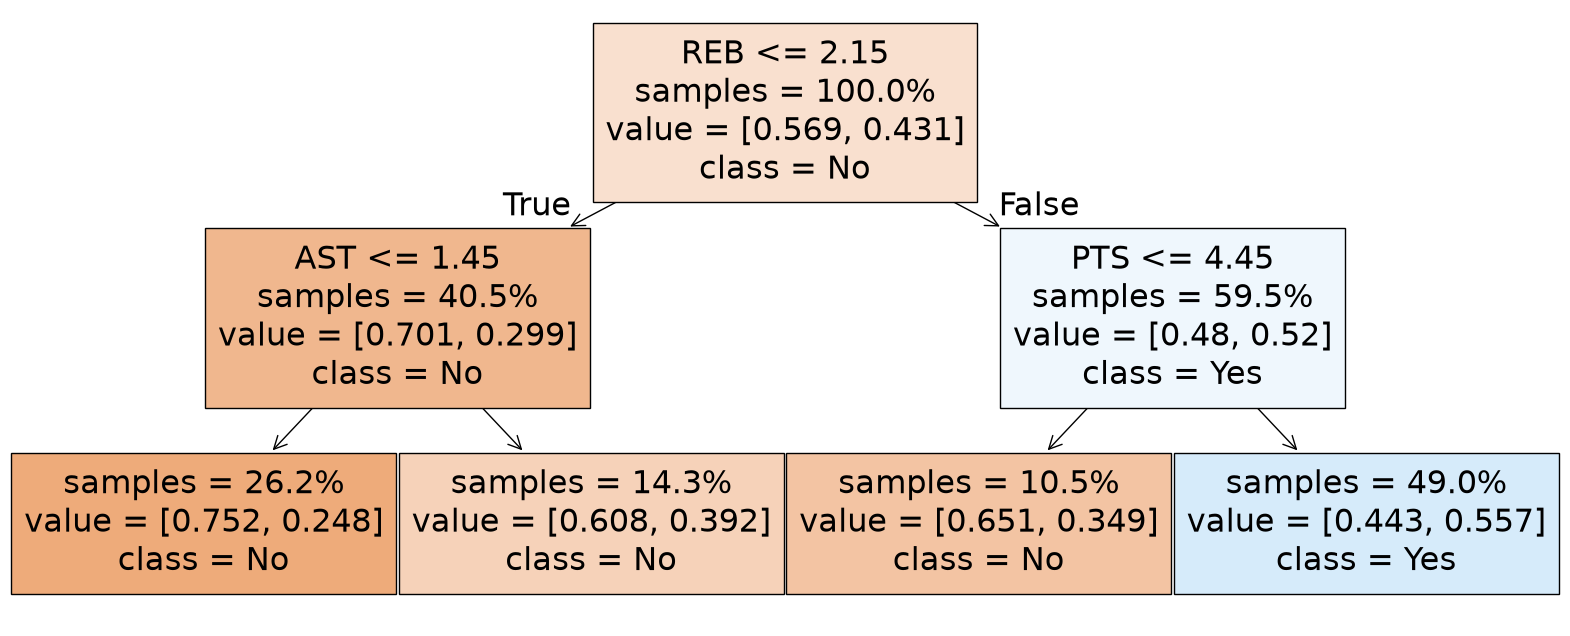

Predicted,0,1
Actual,,
0,114,64
1,51,79


Accuracy: 62.66%



In [104]:
features = ['PTS', 'AST', 'REB']
X = df_rookie_pred[features]
y = df_rookie_pred['still_in_league_5y']
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.8, random_state = 10)

param_grid = {'max_depth': range(1, 10)}
grid_search = GridSearchCV(
    DecisionTreeClassifier(random_state=10), 
    param_grid, 
    cv=5, 
    scoring='accuracy'
)
grid_search.fit(X_train, y_train)

best_depth = grid_search.best_params_['max_depth']
tree_model = grid_search.best_estimator_

print(f"Optimal depth founded: max_depth = {best_depth}")

tree_model = DecisionTreeClassifier(max_depth=best_depth).fit(X_train, y_train)
plot_decision_tree(tree_model)

y_pred = tree_model.predict(X_test)
display(pd.crosstab(y_test, y_pred, rownames=['Actual'], colnames=['Predicted']))
accuracy_basic = accuracy_score(y_test, y_pred) * 100
print(f"Accuracy: {accuracy_basic:.2f}%\n")


This is a first and very intuitive approach. We observe that the first node has a rule on rebounds, and one leaf has a rule on assists, while the other one on points. It makes total sense: there is exactly one node for each feature. A deeper tree may lead to overfitting.

#### 2. Only points
Now we take points as our only feature.

Optimal depth founded: max_depth = 3


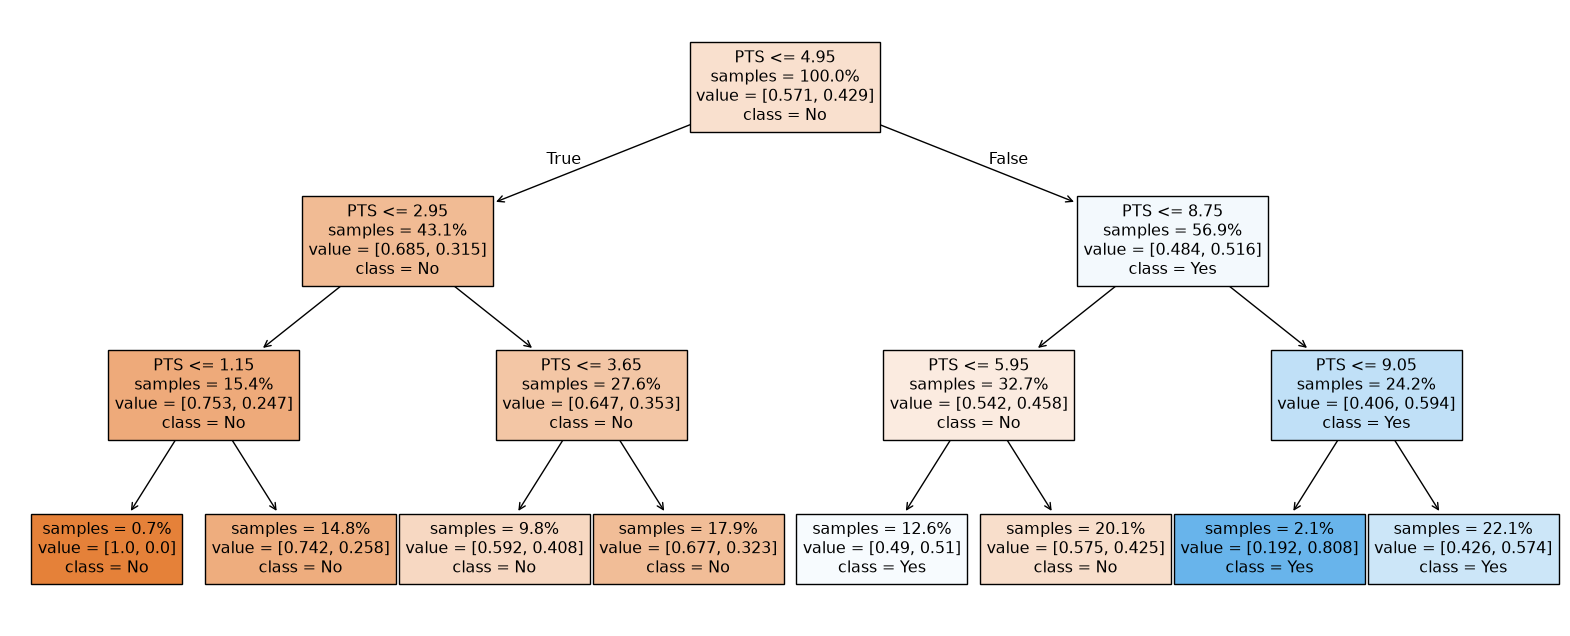

Predicted,0,1
Actual,,
0,123,53
1,75,57


Accuracy: 58.44%



In [117]:
features = ['PTS']
X = df_rookie_pred[features]
y = df_rookie_pred['still_in_league_5y']
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.8, random_state = 11)

param_grid = {'max_depth': range(1, 10)}
grid_search = GridSearchCV(
    DecisionTreeClassifier(random_state=10), 
    param_grid, 
    cv=5, 
    scoring='accuracy'
)
grid_search.fit(X_train, y_train)

best_depth = grid_search.best_params_['max_depth']
tree_model = grid_search.best_estimator_

print(f"Optimal depth founded: max_depth = {best_depth}")

tree_model = DecisionTreeClassifier(max_depth=best_depth).fit(X_train, y_train)
plot_decision_tree(tree_model)

y_pred = tree_model.predict(X_test)
display(pd.crosstab(y_test, y_pred, rownames=['Actual'], colnames=['Predicted']))
accuracy_pts = accuracy_score(y_test, y_pred) * 100
print(f"Accuracy: {accuracy_pts:.2f}%\n")

That's worse than the first one. The classifier that considers not only points, but also assists and rebounds, performs better. From this we can conclude that scoring is not enough, an nba player must also know hot to pass the ball and secure rebounds in order to stay in the league.

#### 3. Playmaking and ball security
Let's see know how the classifier behaves if we only consider variables related to playmaking and ball security, i.e assists and turnovers.

Optimal depth founded: max_depth = 1


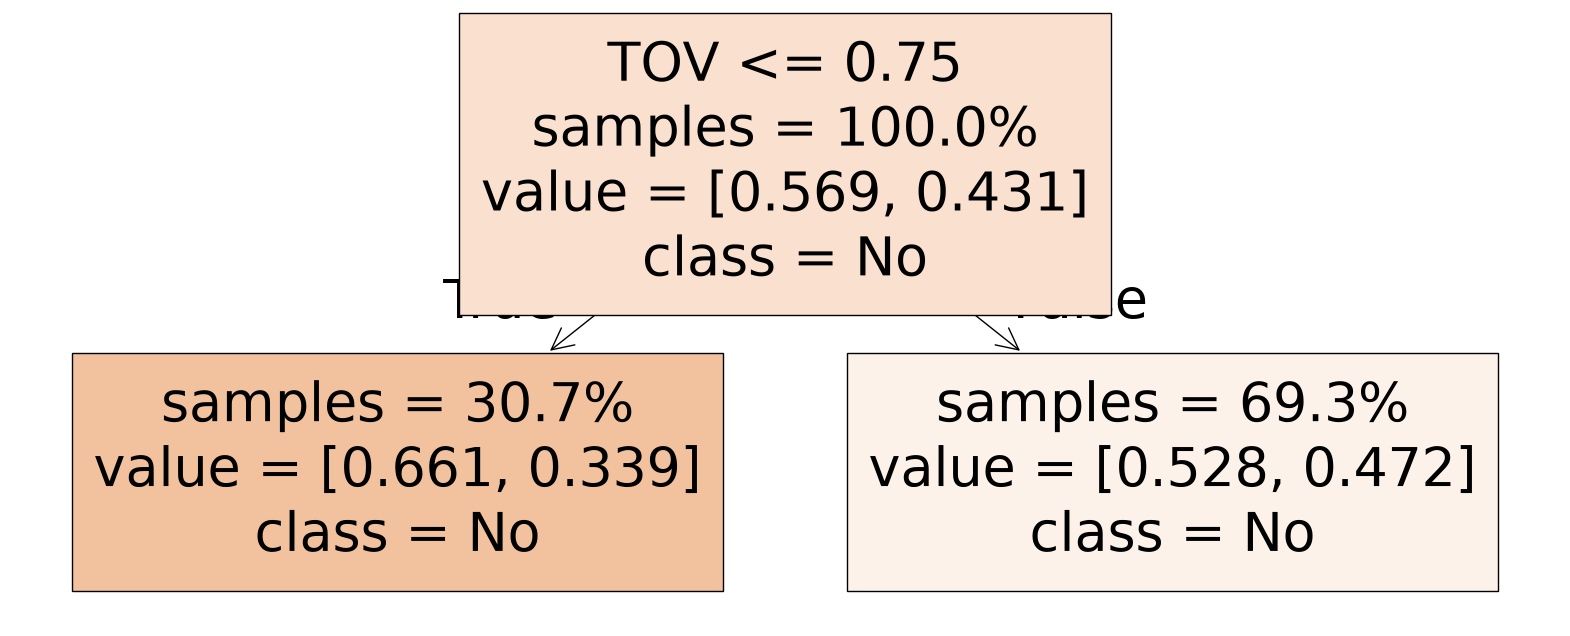

Predicted,0
Actual,
0,178
1,130


Accuracy: 57.79%



In [135]:
features = ['AST','TOV']
X = df_rookie_pred[features]
y = df_rookie_pred['still_in_league_5y']
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.8, random_state = 10)

param_grid = {'max_depth': range(1, 10)}
grid_search = GridSearchCV(
    DecisionTreeClassifier(random_state=10), 
    param_grid, 
    cv=5, 
    scoring='accuracy'
)
grid_search.fit(X_train, y_train)

best_depth = grid_search.best_params_['max_depth']
tree_model = grid_search.best_estimator_

print(f"Optimal depth founded: max_depth = {best_depth}")

tree_model = DecisionTreeClassifier(max_depth=best_depth).fit(X_train, y_train)
plot_decision_tree(tree_model)

y_pred = tree_model.predict(X_test)
display(pd.crosstab(y_test, y_pred, rownames=['Actual'], colnames=['Predicted']))
accuracy_playmaking = accuracy_score(y_test, y_pred) * 100
print(f"Accuracy: {accuracy_playmaking:.2f}%\n")

Not really good. We can interpret this as meaning that players are not expected to be great handlers in their early years. Players with more talent are more valued than more secure players. On the other hand, the `decision tree` always guesses failure. This may be because the features don't give enough information, and since most of the players are not successful, the best the classifier can do is to guess always failure.

#### 4. Hustler player
We will do the same know with another player profile: the hustler player. This is, we only use stats that reflect the effort that the player puts in the court, without the need of having the ball in their hands all the time. We use offensive rebounds, defensive rebounds, steals, blocks and minutes played.

Optimal depth founded: max_depth = 2


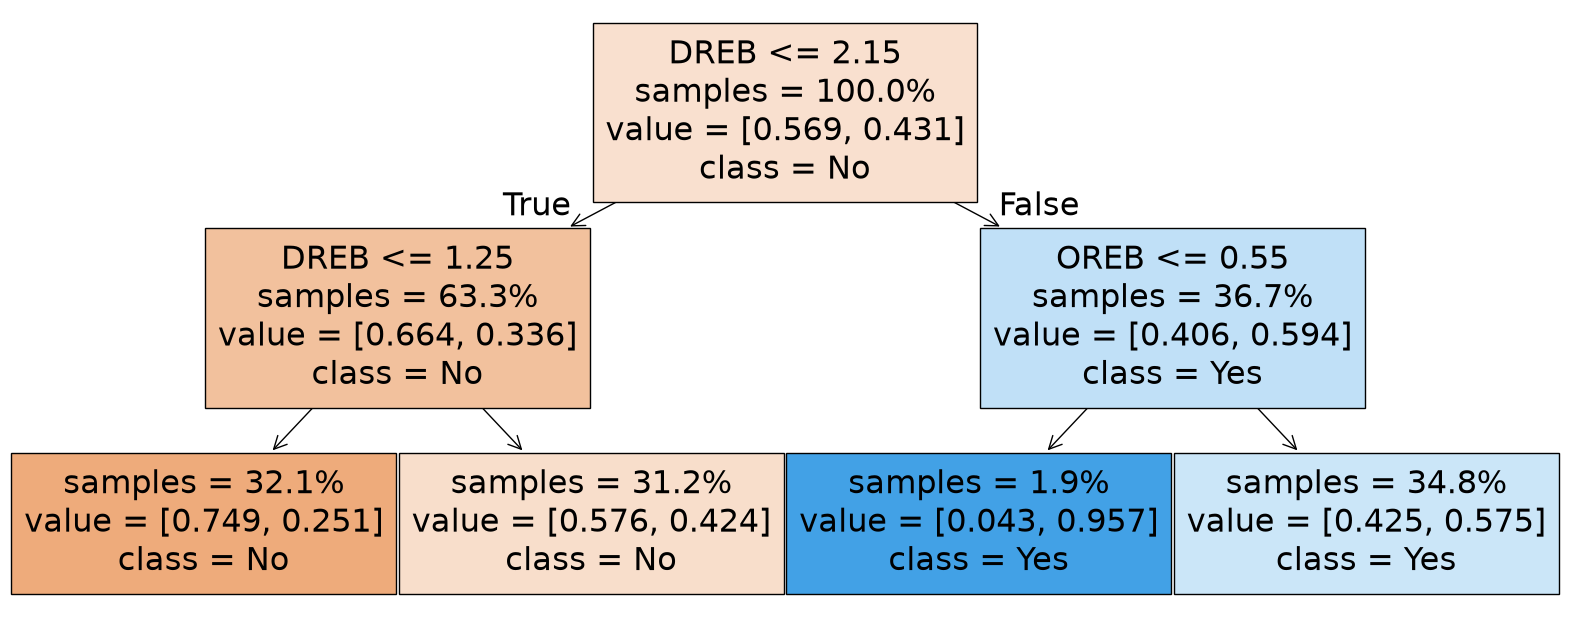

Predicted,0,1
Actual,,
0,126,52
1,66,64


Accuracy: 61.69%



In [139]:
features = ['OREB','DREB','STL','BLK','MIN']
X = df_rookie_pred[features]
y = df_rookie_pred['still_in_league_5y']
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.8, random_state = 10)

param_grid = {'max_depth': range(1, 10)}
grid_search = GridSearchCV(
    DecisionTreeClassifier(random_state=10), 
    param_grid, 
    cv=5, 
    scoring='accuracy'
)
grid_search.fit(X_train, y_train)

best_depth = grid_search.best_params_['max_depth']
tree_model = grid_search.best_estimator_

print(f"Optimal depth founded: max_depth = {best_depth}")

tree_model = DecisionTreeClassifier(max_depth=best_depth).fit(X_train, y_train)
plot_decision_tree(tree_model)

y_pred = tree_model.predict(X_test)
display(pd.crosstab(y_test, y_pred, rownames=['Actual'], colnames=['Predicted']))
accuracy_hustler = accuracy_score(y_test, y_pred) * 100
print(f"Accuracy: {accuracy_hustler:.2f}%\n")

We obtained a similar error to the first model. One could argue that pure scorers who stop making buckets lose their spot quickly, while specialists in rebounding, rim protection, and defensive effort tend to stay in the league longer.

#### 5. Games played
We try now a different single feature input, namely, the ammount of games played.

Optimal depth founded: max_depth = 5


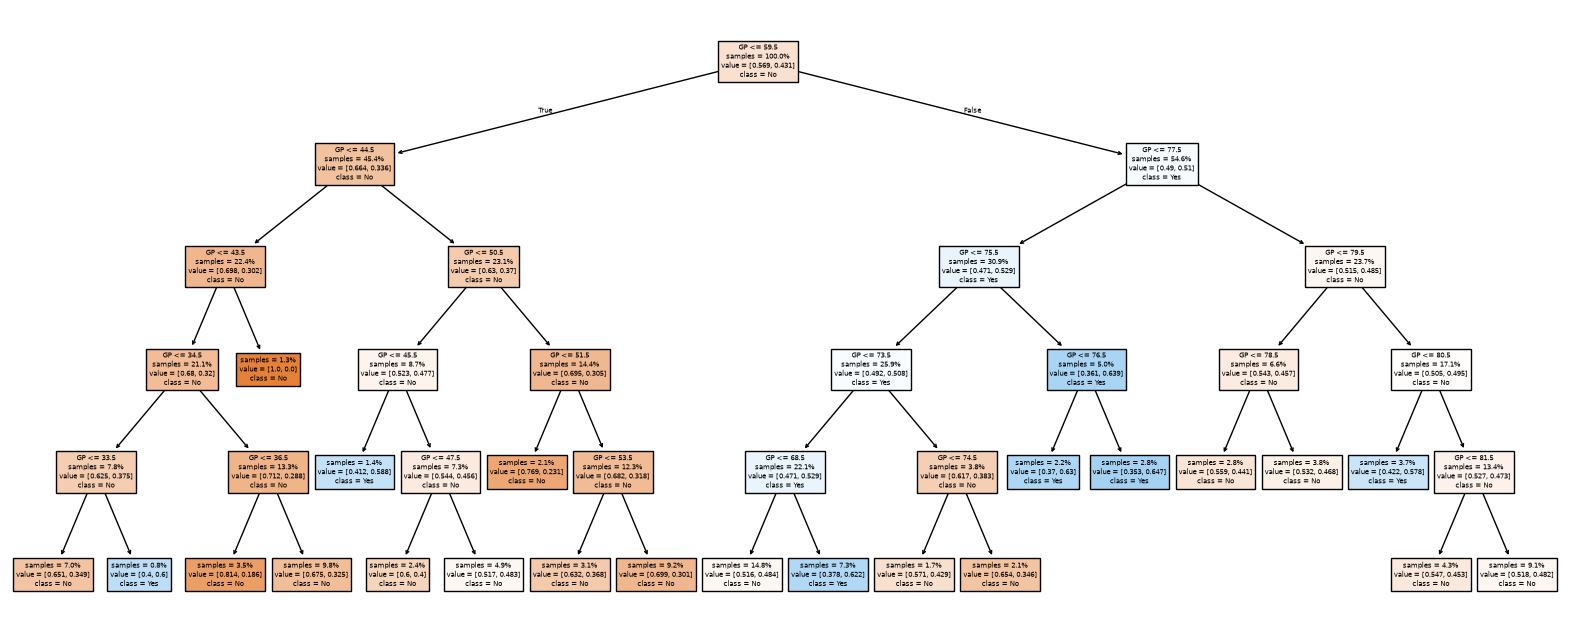

Predicted,0,1
Actual,,
0,149,29
1,97,33


Accuracy: 59.09%



In [207]:
features = ['GP']
X = df_rookie_pred[features]
y = df_rookie_pred['still_in_league_5y']
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.8, random_state = 10)

param_grid = {'max_depth': range(1, 10)}
grid_search = GridSearchCV(
    DecisionTreeClassifier(random_state=10), 
    param_grid, 
    cv=5, 
    scoring='accuracy'
)
grid_search.fit(X_train, y_train)

best_depth = grid_search.best_params_['max_depth']
tree_model = grid_search.best_estimator_

print(f"Optimal depth founded: max_depth = {best_depth}")

tree_model = DecisionTreeClassifier(max_depth=best_depth).fit(X_train, y_train)
plot_decision_tree(tree_model)

y_pred = tree_model.predict(X_test)
display(pd.crosstab(y_test, y_pred, rownames=['Actual'], colnames=['Predicted']))
accuracy_gp = accuracy_score(y_test, y_pred) * 100
print(f"Accuracy: {accuracy_gp:.2f}%\n")

Even though we get the deeper tree so far, we observe that having more minutes in the rookie year is not a good indicator of the player's success. This can be because the amount of minutes a rookie gets depends more on how good the team he lands on is: if the team is worse, he will play a lot of games and viceversa.

#### 6. Offensive player
We now wonder if the league value more offensive or defensive players. We are going to go ahead and train to models, one using only offensive statistics and the other only keeping in mind the defensive stats. Let's start with the offensive profile. The features we will use this time are points, field goals made, 3 pointers made and assists.

Optimal depth founded: max_depth = 2


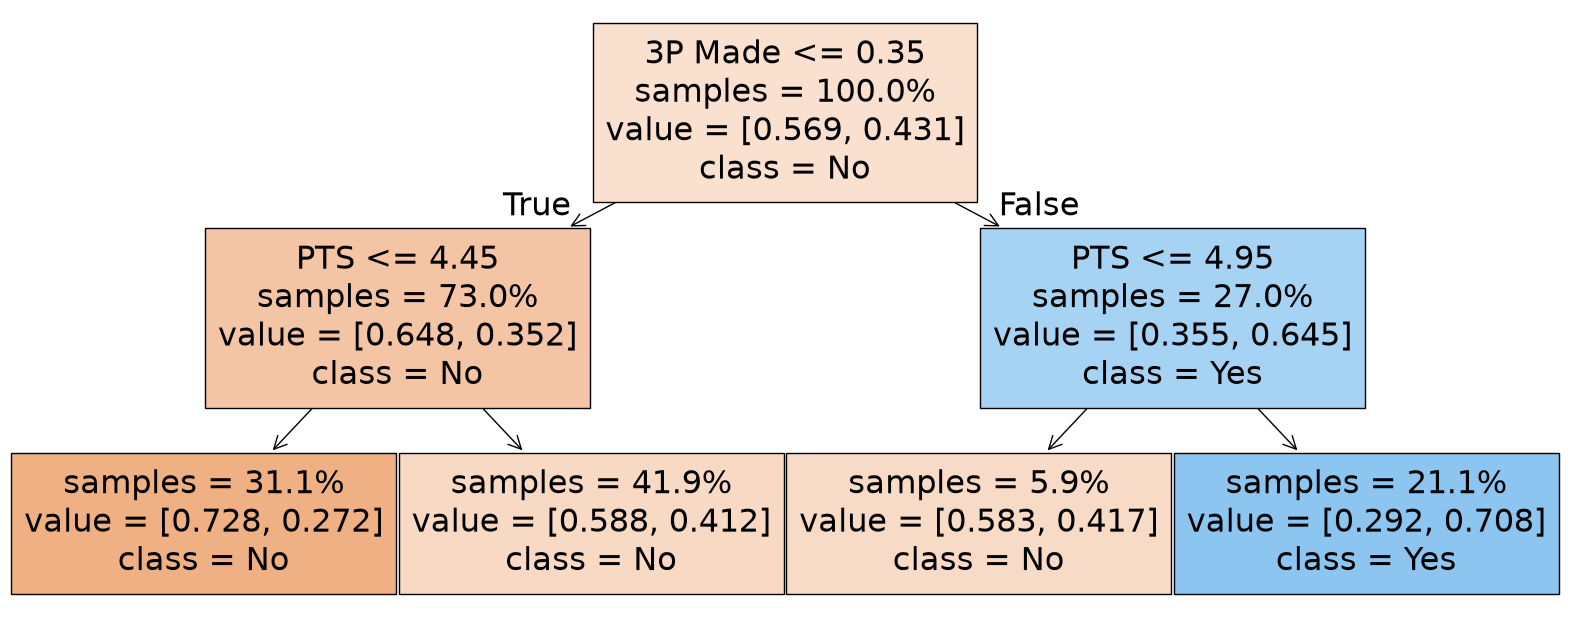

Predicted,0,1
Actual,,
0,163,15
1,80,50


Accuracy: 69.16%



In [145]:
features = ['PTS','FGM', '3P Made', 'AST']
X = df_rookie_pred[features]
y = df_rookie_pred['still_in_league_5y']
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.8, random_state = 10)

param_grid = {'max_depth': range(1, 10)}
grid_search = GridSearchCV(
    DecisionTreeClassifier(random_state=10), 
    param_grid, 
    cv=5, 
    scoring='accuracy'
)
grid_search.fit(X_train, y_train)

best_depth = grid_search.best_params_['max_depth']
tree_model = grid_search.best_estimator_

print(f"Optimal depth founded: max_depth = {best_depth}")

tree_model = DecisionTreeClassifier(max_depth=best_depth).fit(X_train, y_train)
plot_decision_tree(tree_model)

y_pred = tree_model.predict(X_test)
display(pd.crosstab(y_test, y_pred, rownames=['Actual'], colnames=['Predicted']))
accuracy_offense = accuracy_score(y_test, y_pred) * 100
print(f"Accuracy: {accuracy_offense:.2f}%\n")

Best one so far. If we take into account all offensive statistics, our classifier behaves really well. This reflects a reality: talented players on the offensive end of the court have a secured spot in the league.

#### 7. Defensive player
We are going to go ahead and try the same strategy, but this time only with defensive features.

Optimal depth founded: max_depth = 5


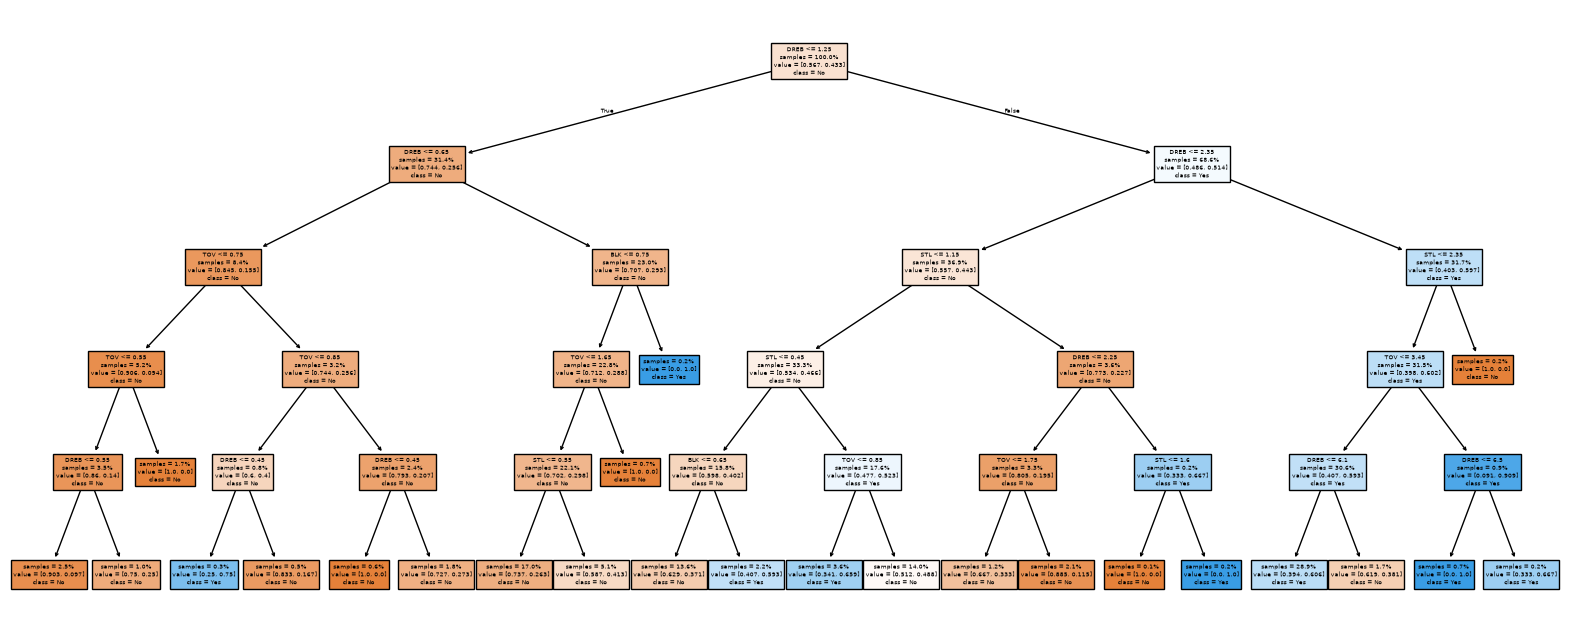

Predicted,0,1
Actual,,
0,132,49
1,63,64


Accuracy: 63.64%



In [153]:
features = ['DREB','STL', 'BLK', 'TOV']
X = df_rookie_pred[features]
y = df_rookie_pred['still_in_league_5y']
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.8, random_state = 7)

param_grid = {'max_depth': range(1, 10)}
grid_search = GridSearchCV(
    DecisionTreeClassifier(random_state=10), 
    param_grid, 
    cv=5, 
    scoring='accuracy'
)
grid_search.fit(X_train, y_train)

best_depth = grid_search.best_params_['max_depth']
tree_model = grid_search.best_estimator_

print(f"Optimal depth founded: max_depth = {best_depth}")

tree_model = DecisionTreeClassifier(max_depth=best_depth).fit(X_train, y_train)
plot_decision_tree(tree_model)

y_pred = tree_model.predict(X_test)
display(pd.crosstab(y_test, y_pred, rownames=['Actual'], colnames=['Predicted']))
accuracy_defense = accuracy_score(y_test, y_pred) * 100
print(f"Accuracy: {accuracy_defense:.2f}%\n")

The model that awards the offensive profiles is slightly more accurate than the one that gives more importance to defense. From this, we could argue a few points:
* Offensive production is a stronger predictor of a rookie's longevity than defensive contributions.
* Traditional defensive measures such as the ones used for the defensive player tree don't capture defensive contributions as well as the classical offensive measures capture the offensive ones. Advance statistics could be used to constrast this hypothesis.
* Elite offensive player are hard to find, while defensive profiles are much more repleceable.

#### 8. Shooting percentages
All the features we have used yet don't consider a very important aspect of the game: efficiency. We will build a model now that uses the features about shooting percentages (field goals percentage, 3 pointers percentage and free throws percentage). For this task, we have to delete first some rows (players) that don't have information about percentages.

Optimal depth founded: max_depth = 1


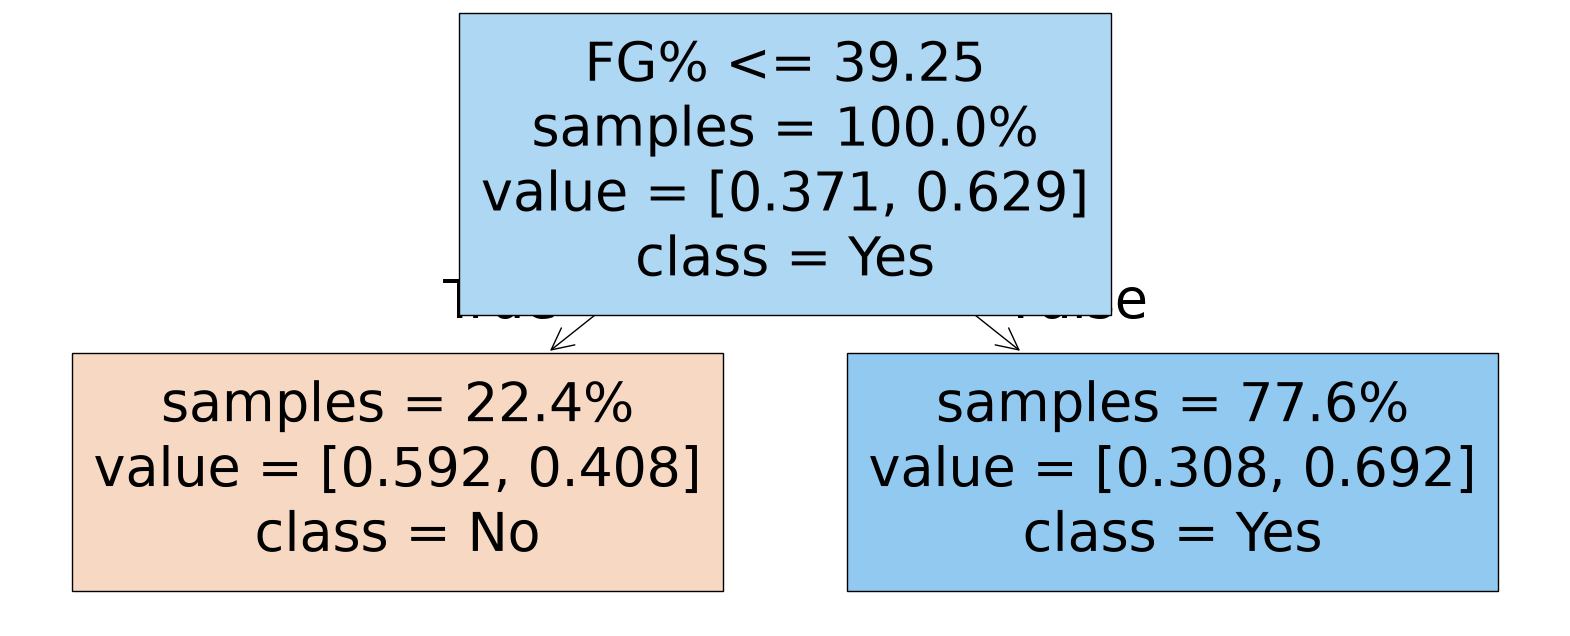

Predicted,0,1
Actual,,
0,27,36
1,15,57


Accuracy: 62.22%



In [162]:
features = ['FG%', '3P%', 'FT%']

for col in features:
    df_rookie_pred[col] = pd.to_numeric(df_rookie_pred[col], errors='coerce')

df_clean = df_rookie_pred.dropna()

X = df_clean[features]
y = df_clean['still_in_league_5y']

X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.8, random_state = 10)

param_grid = {'max_depth': range(1, 10)}
grid_search = GridSearchCV(
    DecisionTreeClassifier(random_state=10), 
    param_grid, 
    cv=5, 
    scoring='accuracy'
)
grid_search.fit(X_train, y_train)

best_depth = grid_search.best_params_['max_depth']
tree_model = grid_search.best_estimator_

print(f"Optimal depth founded: max_depth = {best_depth}")

tree_model = DecisionTreeClassifier(max_depth=best_depth).fit(X_train, y_train)
plot_decision_tree(tree_model)

y_pred = tree_model.predict(X_test)
display(pd.crosstab(y_test, y_pred, rownames=['Actual'], colnames=['Predicted']))
accuracy_percentage = accuracy_score(y_test, y_pred) * 100
print(f"Accuracy: {accuracy_percentage:.2f}%\n")

It only pays attention to field goal percentage, which makes sense since almost all players have decent free throws percentage and 3 pointers percentage are included in the field goal percentage. The acceptable performance of the model can be because most rookies that enter the NBA struggle with percentages because the game gets more physical, and players that perform well on this aspect of the game usially gain directly a spot in the league.

#### 9. Efficiencient player
Next, we will only use efficiency stat (EFF).

Optimal depth founded: max_depth = 2


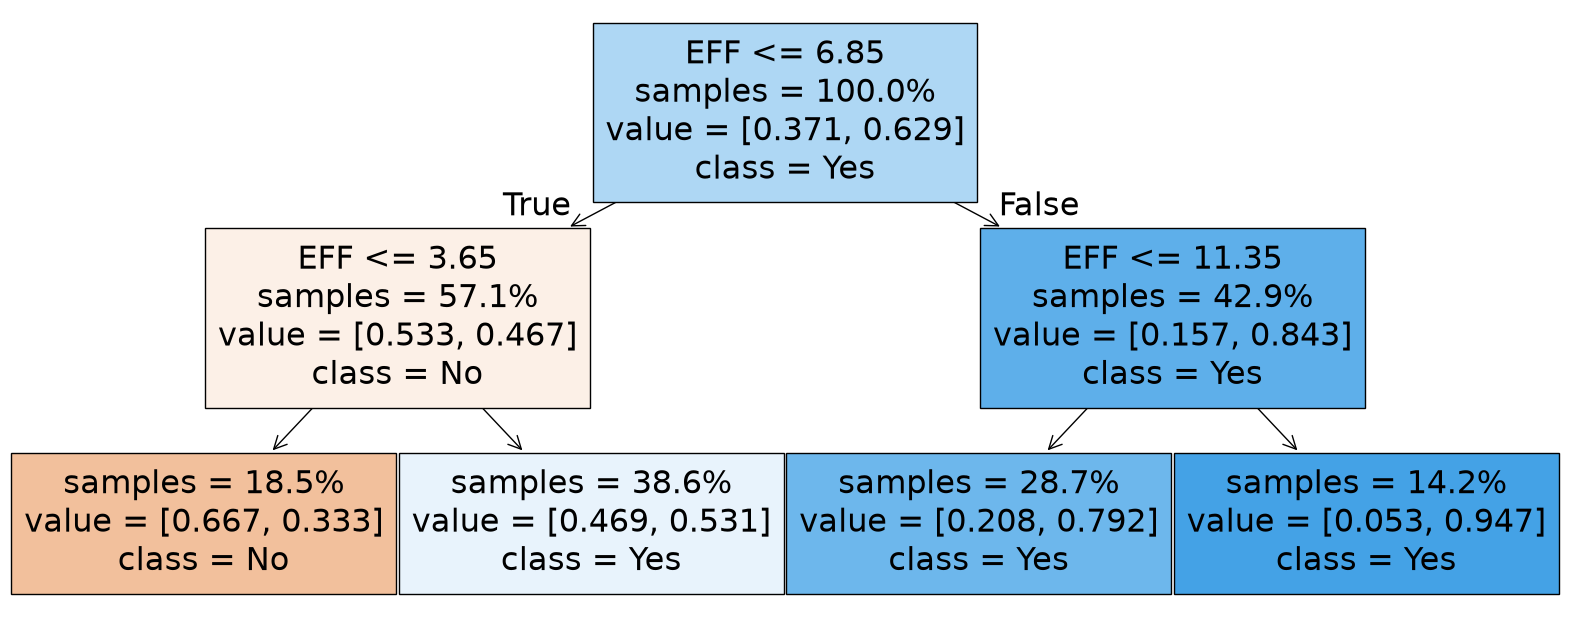

Predicted,0,1
Actual,,
0,22,41
1,7,65


Accuracy: 64.44%



In [210]:
features = ['EFF']

X = df_clean[features]
y = df_clean['still_in_league_5y']

X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.8, random_state = 10)

param_grid = {'max_depth': range(1, 10)}
grid_search = GridSearchCV(
    DecisionTreeClassifier(random_state=10), 
    param_grid, 
    cv=5, 
    scoring='accuracy'
)
grid_search.fit(X_train, y_train)

best_depth = grid_search.best_params_['max_depth']
tree_model = grid_search.best_estimator_

print(f"Optimal depth founded: max_depth = {best_depth}")

tree_model = DecisionTreeClassifier(max_depth=best_depth).fit(X_train, y_train)
plot_decision_tree(tree_model)

y_pred = tree_model.predict(X_test)
display(pd.crosstab(y_test, y_pred, rownames=['Actual'], colnames=['Predicted']))
accuracy_percentage_eff = accuracy_score(y_test, y_pred) * 100
print(f"Accuracy: {accuracy_percentage_eff:.2f}%\n")

This was the best performance by a model based on a single feature. It makes total sense, since the efficiency stat takes into account all aspects of the game. Also, efficiency is a high valued aspect in the game of a rookie because it is a good indicator of the maturity of a player, and more matured players are easier to develop. Therefore, they are tipically still in the league after 5 years.

#### 10. Team win percentage
Is the team the rookie lands on important? Let's check. We are going to build a classifier that only uses the win percentage of the team

Optimal depth founded: max_depth = 1


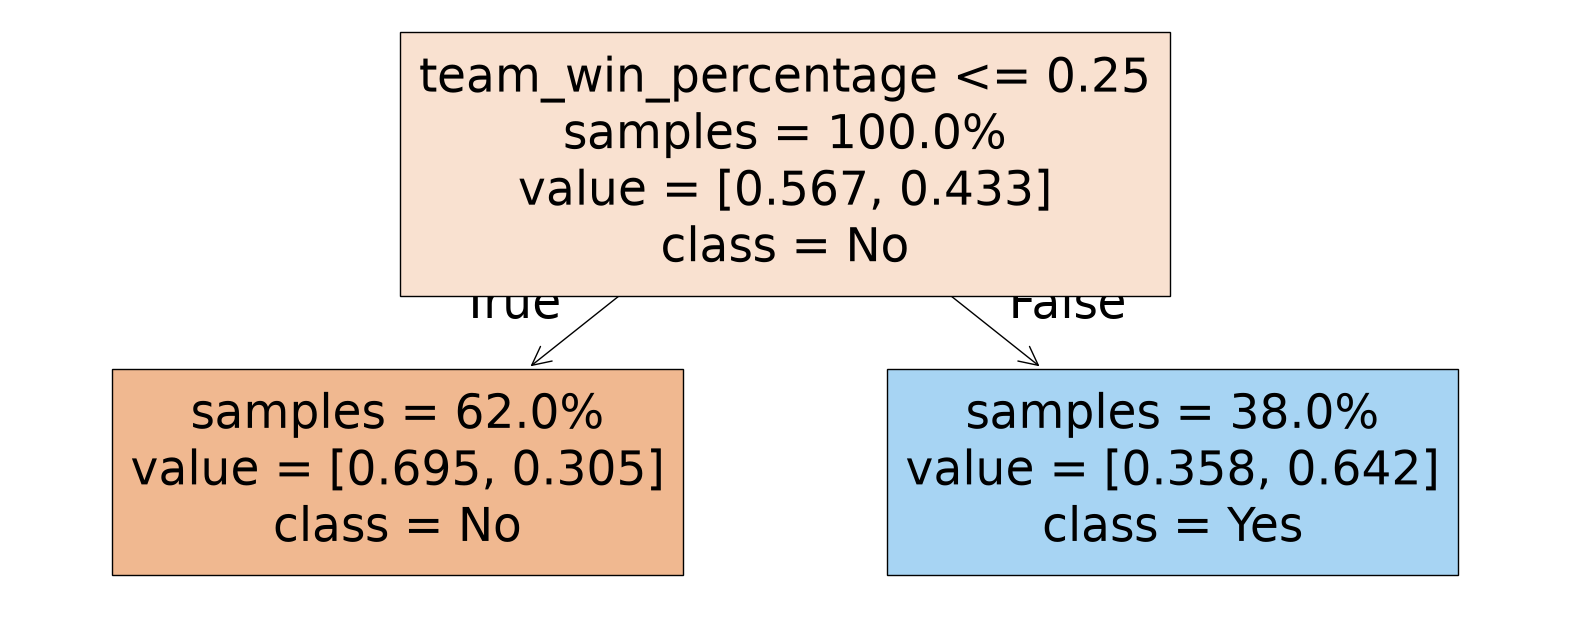

Predicted,0,1
Actual,,
0,126,55
1,53,74


Accuracy: 64.94%



In [191]:
features = ['team_win_percentage']
X = df_rookie_pred[features]
y = df_rookie_pred['still_in_league_5y']
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.8, random_state = 7)

param_grid = {'max_depth': range(1, 10)}
grid_search = GridSearchCV(
    DecisionTreeClassifier(random_state=7), 
    param_grid, 
    cv=5, 
    scoring='accuracy'
)
grid_search.fit(X_train, y_train)

best_depth = grid_search.best_params_['max_depth']
tree_model = grid_search.best_estimator_

print(f"Optimal depth founded: max_depth = {best_depth}")

tree_model = DecisionTreeClassifier(max_depth=best_depth).fit(X_train, y_train)
plot_decision_tree(tree_model)

y_pred = tree_model.predict(X_test)
display(pd.crosstab(y_test, y_pred, rownames=['Actual'], colnames=['Predicted']))
accuracy_team_wins = accuracy_score(y_test, y_pred) * 100
print(f"Accuracy: {accuracy_team_wins:.2f}%\n")

The model shows that rookies that land in very bad teams are not usually successful in the league. This may be because in teams with a winning culture are better developing their rookies (maybe because the player more motivated to perform well or because the coaching staff is better).

We also observe that this single input feature model performs better than when we only considered points, which is a bit unexpected. This indicates that the win percentage of the rookies' team determines more accurately the success of the player than the points.

#### 11. Relevance in team
What about the importance of the player in the team? Let's take into account the minutes in court, 3 pointers attempt and field goals attempts.

Optimal depth founded: max_depth = 3


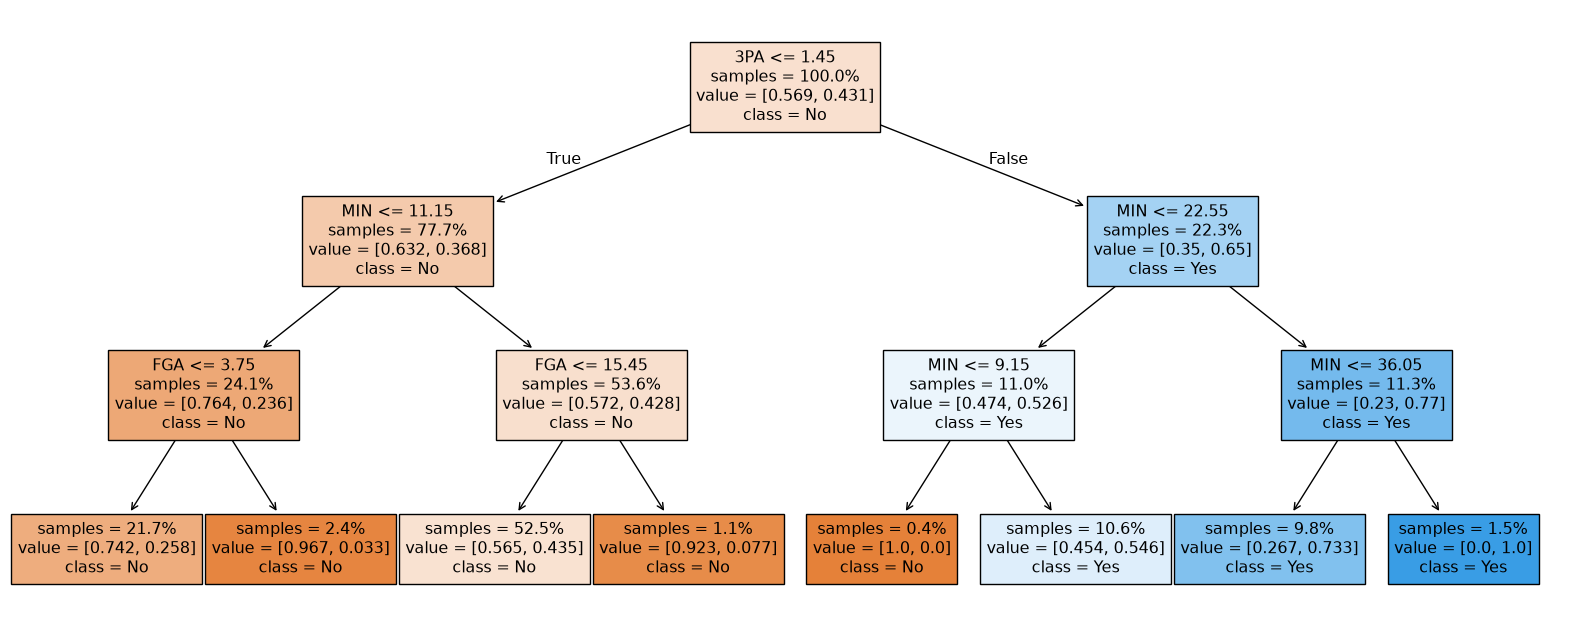

Predicted,0,1
Actual,,
0,161,17
1,87,43


Accuracy: 66.23%



In [193]:
features = ['MIN','3PA','FGA']
X = df_rookie_pred[features]
y = df_rookie_pred['still_in_league_5y']
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.8, random_state = 10)

param_grid = {'max_depth': range(1, 10)}
grid_search = GridSearchCV(
    DecisionTreeClassifier(random_state=10), 
    param_grid, 
    cv=5, 
    scoring='accuracy'
)
grid_search.fit(X_train, y_train)

best_depth = grid_search.best_params_['max_depth']
tree_model = grid_search.best_estimator_

print(f"Optimal depth founded: max_depth = {best_depth}")

tree_model = DecisionTreeClassifier(max_depth=best_depth).fit(X_train, y_train)
plot_decision_tree(tree_model)

y_pred = tree_model.predict(X_test)
display(pd.crosstab(y_test, y_pred, rownames=['Actual'], colnames=['Predicted']))
accuracy_team_relevance = accuracy_score(y_test, y_pred) * 100
print(f"Accuracy: {accuracy_team_relevance:.2f}%\n")

It performs fairly well. The confidence that the coach and teammates have in the rookie are a good indicator of the success or failure of the player.

#### 12. All features
Just to see how well we can build a classifier, let's take all the features into account.

Optimal depth founded: max_depth = 4


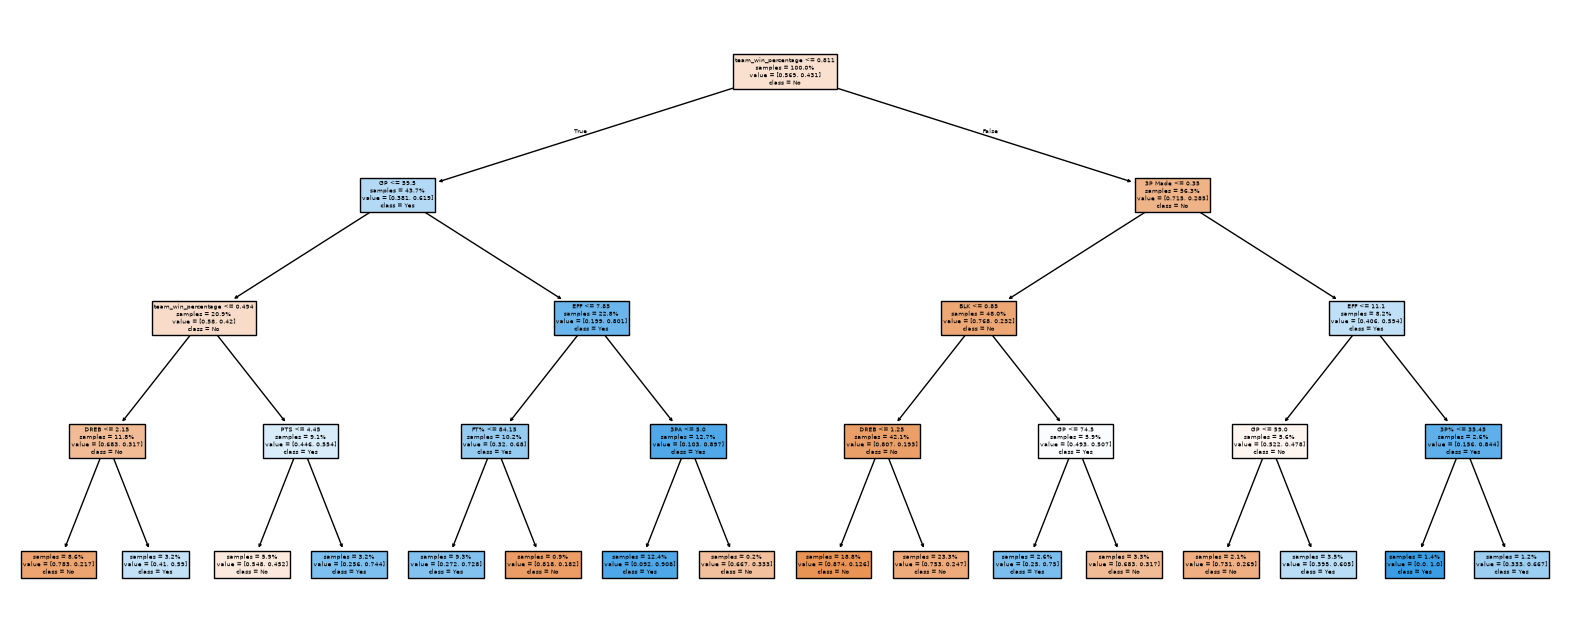

Predicted,0,1
Actual,,
0,147,31
1,52,78


Accuracy: 73.05%



In [194]:
features = ['GP','MIN','PTS','FGM','FGA','FG%','3P Made','3PA','3P%','FTM','FT%','OREB','DREB','REB','AST','STL','BLK','TOV','EFF','team_win_percentage']
X = df_rookie_pred[features]
y = df_rookie_pred['still_in_league_5y']
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.8, random_state = 10)

param_grid = {'max_depth': range(1, 10)}
grid_search = GridSearchCV(
    DecisionTreeClassifier(random_state=10), 
    param_grid, 
    cv=5, 
    scoring='accuracy'
)
grid_search.fit(X_train, y_train)

best_depth = grid_search.best_params_['max_depth']
tree_model = grid_search.best_estimator_

print(f"Optimal depth founded: max_depth = {best_depth}")

tree_model = DecisionTreeClassifier(max_depth=best_depth).fit(X_train, y_train)
plot_decision_tree(tree_model)

y_pred = tree_model.predict(X_test)
display(pd.crosstab(y_test, y_pred, rownames=['Actual'], colnames=['Predicted']))
accuracy_all_features = accuracy_score(y_test, y_pred) * 100
print(f"Accuracy: {accuracy_all_features:.2f}%\n")

This was the best one so far, and we got a decent accuracy. Trivially, if we consider all features the classifier will perform better.

## **STEP 4: FINAL CONCLUSIONS**

We present a histogram with the accuracy of each `decision tree`:

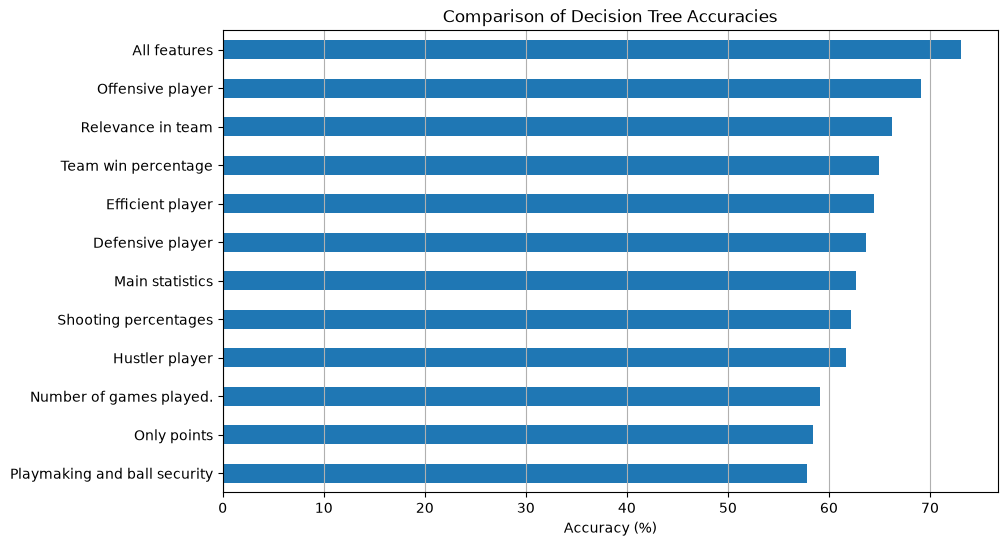

In [211]:
labels = [
    "Main statistics",
    "Only points",
    "Playmaking and ball security",
    "Hustler player",
    "Number of games played.",
    "Offensive player",
    "Defensive player",
    "Shooting percentages",
    "Efficient player",
    "Team win percentage",
    "Relevance in team",
    "All features"
]

accuracies = [
    accuracy_basic, accuracy_pts, accuracy_playmaking, accuracy_hustler,
    accuracy_gp, accuracy_offense, accuracy_defense, accuracy_percentage,
    accuracy_percentage_eff, accuracy_team_wins, accuracy_team_relevance, 
    accuracy_all_features
]

pd.Series(accuracies, index=labels).sort_values().plot(
    kind='barh', 
    figsize=(10, 6),
)

plt.xlabel('Accuracy (%)')
plt.title('Comparison of Decision Tree Accuracies')
plt.grid(axis='x')
plt.show()

We see clearly in the graphic representation some of the facts we already discussed. Let's go briefly over the observations we made during the project just to get a final picture of the key factors behind NBA player success.

1. **Main statistics over only points:** When we used points, rebounds and assists to train the model instead of just points, the model performed better on the test set. This means that NBA players must have complete profiles in order to succeed, it is not enough to be a decent scorer.
2. **Rookies are not expected to be trustworthy:** The model for the features of playmaking and ball security didn't perform well and always guessed failure. A possible explanation is that these stats don't determine the longevity of a rookie because players are not expected to take great care of the ball in their early years, and since most of the rookies are not in the league after 5 years, the best the classifier can do is to guess always failure.
3. **Success of the hustler player:** The hustler player model performed as well as considering the main statistics. That is because players that put in effort secure easily a spot in the roaster and they are usually able to perform at the same level. However, rookies whose performance depends on how many points score, how many assists make or how many rebounds grab, lose rotation minutes more easily.
4. **Games played is not a good indicator:** The model that only consider the minutes that a rookie played per game didn't perform well. This can mean that the amount of minutes on the court says more about the team, rather than the performance of the player: teams with deeper roasters will give less minutes to their rookies, while the shalower teams will tend to do the opposite.
5. **Offensive vs defensive rookies:** The model based on offensive features performed much better than the one that only used defensive stats. In fact, the offensive model offered the second best accuracy on the test set (only behind the model of all features). We argued that this can be for different reasons. One of the reasons may be that the offensive stats represent better the player's performance than the deffensive stats, and we should use advanced statistics for the defensive model. The other disscused reason was that great offensive player are rarer than specialists in defense.
6. **Acceptable performance of percentages model:** The classifier that used the shooting percentages performed well, and this was explained by arguing that rookies with good shooting percentages outstand and gain a spot on the roaster because players in their first year don't usually have a good shot selection.
7. **Efficiency was the best feature:** The efficiency stat gave us the single feature model with highest accuracy. We argued that this is because of two reasons. First, because the efficiency stat is based in almost all importants stats of the game. The second reason was that players with a decent efficiency are very rare and high valued by franchises and coaches in the NBA.
8. **Winning culture teams:** We trained a decision tree only using the rookies' team win percentage. The performance was not too bad, and the structure of the classifier told us that teams with higher win percentage are more successful with their rookies. This may be because players that are developed in winning teams have to put in more effort to have a spot in the team, since the roaster is more talented. A simpler explanation is that better teams have better coaching staff. We also observed that this model performed better that when we only used points, from what we conclude that, statistically, the team the rookies land on is more determinant than the amount of scored points.
9. **Players with more opportunities have success:** The model trained using the features that indicate the relevance of the player on the team when they are in court was the third model with better accuracy on the test set. We can conclude that rookies who earn the trust of their coaching staff and franchise tend to have longer careers in the league.
10. **All features are relevant:** Finally, the model trained with all available features resulted in the better accuracy. We conclude that all features are important, and to get a more competent model, we would try to gather more features about the game in order to obtain the classifier that can be used in the real world.

#### **COMENTS ON THE PERFORMANCE OF DECISION TREES**
As we disscused, everything indicates that more features would give as better accuracy without changing the initial idea for our classifiers. However, the reason because we didn't obtain a great classifier may not lie in the dataset. It is possible that the problem was the type of classifier used: the decision tree. We enumerate some reasons why this classifier may not have performed as well as expected:

1. **Rigid division vs continuous relations:** Decision trees make strict partitions with numeric inequalities. This may have been a problem for our task, because relations between statistics and permanence in the league are usually smooth and continuous.
2. **Overfitting:** A single decision tree is sensible to the training set in the sense that it tries to explain every atipic case. For example, a very good player that had a season ending injury a few games into the season or a player that took some years to become a good player.
3. **Class imbalance bias:** Most rookies don't make it to year 5. Thus, the decision tree sistematically tends to guess failure. They prioritize the majority class.

